In [50]:
import pandas as pd
from pathlib import Path
from pyproj import Transformer
folder = Path("FixedBikes")
df_fixed_bikes = {}

transformer = Transformer.from_crs("EPSG:25832", "EPSG:4326", always_xy=True)
for item in folder.iterdir():
    if item.is_file():
        df = pd.read_excel(item)
        
        col_check = ['kl.00-01', 'kl.01-02', 'kl.02-03', 'kl.03-04', 'kl.04-05', 'kl.05-06',
       'kl.06-07', 'kl.07-08', 'kl.08-09', 'kl.09-10', 'kl.10-11', 'kl.11-12',
       'kl.12-13', 'kl.13-14', 'kl.14-15', 'kl.15-16', 'kl.16-17', 'kl.17-18',
       'kl.18-19', 'kl.19-20', 'kl.20-21', 'kl.21-22', 'kl.22-23', 'kl.23-24']
            
        df.drop(columns=["Spor"])
        df = df[~(df[col_check] == 0).all(axis=1)]
        hour_cols = [col for col in df.columns if col.startswith("kl.")]
        id_cols = [col for col in df.columns if col not in hour_cols]
        
        df[hour_cols] = df[hour_cols].fillna(0)
        # 2. Unpivot (melt) the hourly columns into rows
        df_long = df.melt(
            id_vars=id_cols,
            value_vars=hour_cols,
            var_name="hour_range",
            value_name="bike_count",
        )
        
        # 3. Combine 'Dato' and the start hour from 'kl.XX-YY' into a datetime column
        dates = pd.to_datetime(df_long["Dato"], format="%d.%m.%Y")
        hours = df_long["hour_range"].str.extract(r"kl\.(\d{2})")[0].astype(int)
        
        df_long["timestamp"] = dates + pd.to_timedelta(hours, unit="h")
        
        # 4. Drop helper columns and sort chronologically
        df_long = (
            df_long.drop(columns=["Dato", "hour_range"])
            .sort_values(["Vej-Id", "Spor", "timestamp"])
            .reset_index(drop=True)
        )

        # 2. Convert entire Pandas columns at once (vectorized)
        df_long["Xkoordinat"], df_long["Ykoordinat"] = transformer.transform(
            df_long["Xkoordinat"].to_numpy(),
            df_long["Ykoordinat"].to_numpy(),
        )
        df_long["hour"] = df_long["timestamp"].dt.hour
        name = (item.name).split("cykeltaellinger-")
        df_fixed_bikes[int(name[1][0:4])] = df_long

In [51]:
for key in df_fixed_bikes:
    print(key)

2011
2013
2005
2008
2006
2009
2010
2007
2012


# Example data for 2013

In [59]:
current_date = 2008

In [56]:
df_fixed_bikes[current_date].head()

,Vej-Id,Vejnavn,Spor,Xkoordinat,Ykoordinat,bike_count,timestamp,hour
0,101 1011358-0 0/ 15 +1,Dr. Louises Bro ( ml. Nørrebrogade og Frederik...,1.0,12.564408,55.686473,4.0,2012-01-16 00:00:00,0
1,101 1011358-0 0/ 15 +1,Dr. Louises Bro ( ml. Nørrebrogade og Frederik...,1.0,12.564408,55.686473,1.0,2012-01-16 01:00:00,1
2,101 1011358-0 0/ 15 +1,Dr. Louises Bro ( ml. Nørrebrogade og Frederik...,1.0,12.564408,55.686473,3.0,2012-01-16 02:00:00,2
3,101 1011358-0 0/ 15 +1,Dr. Louises Bro ( ml. Nørrebrogade og Frederik...,1.0,12.564408,55.686473,1.0,2012-01-16 03:00:00,3
4,101 1011358-0 0/ 15 +1,Dr. Louises Bro ( ml. Nørrebrogade og Frederik...,1.0,12.564408,55.686473,1.0,2012-01-16 04:00:00,4


In [57]:
# Group by hour to see peak times
hourly_counts = df_fixed_bikes[current_date].groupby('hour')['bike_count'].sum().reset_index()
print("Hourly bike count totals:")
display(hourly_counts)

Hourly bike count totals:


,hour,bike_count
0,0,617146.0
1,1,460187.0
2,2,359924.0
3,3,279399.0
4,4,263447.0
5,5,402339.0
6,6,1073990.0
7,7,2504958.0
8,8,3122576.0
9,9,1992649.0


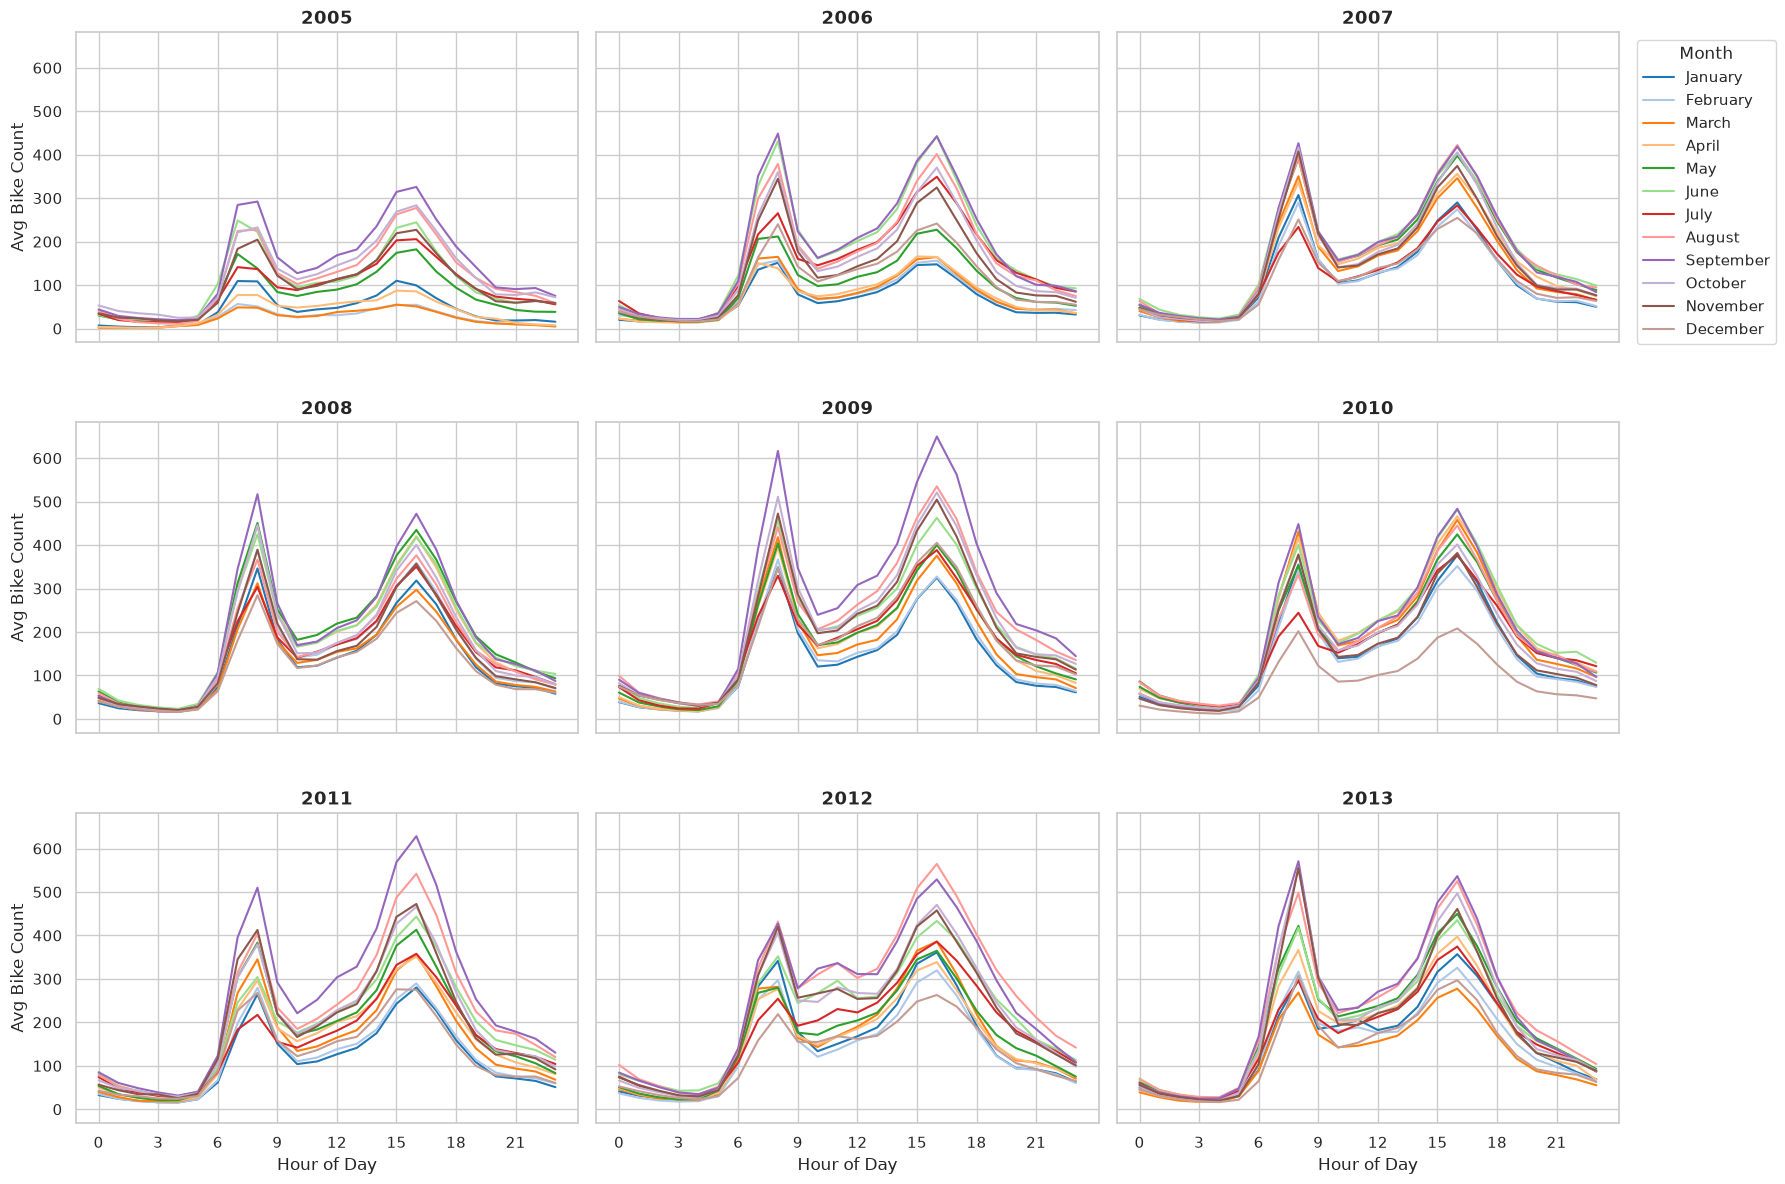

In [62]:
import calendar
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
month_order = list(calendar.month_name[1:])

fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, year in enumerate(sorted(df_fixed_bikes.keys())):
    ax = axes[i]
    df_year = df_fixed_bikes[year].copy()
    df_year["month_name"] = df_year["timestamp"].dt.strftime("%B")
    df_year["hour"] = df_year["timestamp"].dt.hour

    month_hour_counts = (
        df_year.groupby(["month_name", "hour"], as_index=False)["bike_count"]
        .mean()
    )
    month_hour_counts["month_name"] = pd.Categorical(
        month_hour_counts["month_name"], categories=month_order, ordered=True
    )
    month_hour_counts = month_hour_counts.sort_values(["month_name", "hour"])

    sns.lineplot(
        data=month_hour_counts,
        x="hour",
        y="bike_count",
        hue="month_name",
        palette="tab20",
        ax=ax,
        legend=(i == 2),  # Place one shared legend on the top-right subplot
    )

    ax.set_title(str(year), fontsize=13, fontweight="bold")
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Avg Bike Count")
    ax.set_xticks(range(0, 24, 3))

axes[2].legend(title="Month", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

These graphs show when people on average are biking per month, you can clearly see through the graphs the spikes when people are biking to work vs during lunch time when most people are at work so not many people are biking. 

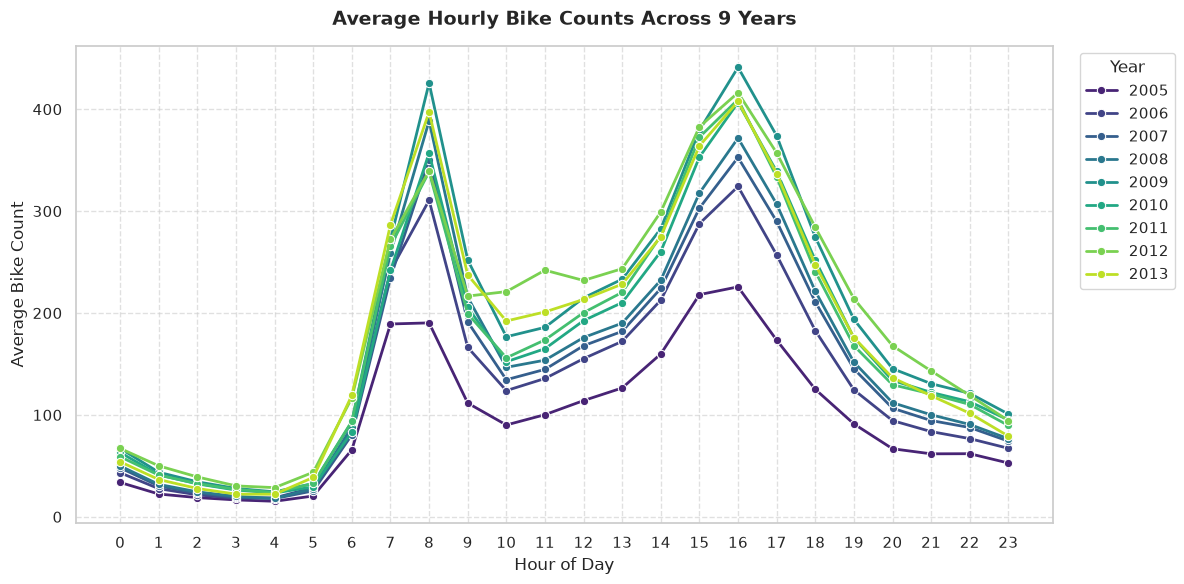

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Merge the dictionary into a single DataFrame using the dict keys as 'year'
df_all = (
    pd.concat(df_fixed_bikes, names=["year"])
    .reset_index(level="year")
    .reset_index(drop=True)
)

df_all["year"] = df_all["year"].astype(int)
df_all["hour"] = df_all["timestamp"].dt.hour

# 2. Aggregate by year and hour
# (.mean() prevents missing sensor days in one year from skewing the comparison;
#  swap to .sum() if you want total yearly counts per hour)
year_hour_counts = (
    df_all.groupby(["year", "hour"], as_index=False)["bike_count"]
    .mean()
)

# 3. Order years chronologically as categories so all 9 appear in the legend
year_order = sorted(year_hour_counts["year"].unique())
year_hour_counts["year"] = pd.Categorical(
    year_hour_counts["year"], categories=year_order, ordered=True
)
year_hour_counts = year_hour_counts.sort_values(["year", "hour"])

# 4. Plot the 9-year hourly comparison
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
sns.lineplot(
    data=year_hour_counts,
    x="hour",
    y="bike_count",
    hue="year",
    marker="o",
    linewidth=2,
    palette="viridis",  # Sequential gradient from earliest to latest year
)

plt.title("Average Hourly Bike Counts Across 9 Years", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Average Bike Count", fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

Overtime more people biked with the most poeple biking overall in 2009 and the least people biking was in 2005, presumably because of more bikelanes being put in the city over time and improved bike infrastucture

In [64]:
# 1. Combine all 9 years into a single DataFrame
df_all = pd.concat(df_fixed_bikes.values(), ignore_index=True)
df_all["month"] = df_all["timestamp"].dt.strftime("%B")

# 2. Rank months by average hourly bike count (highest to lowest)
top_months = (
    df_all.groupby("month", as_index=False)["bike_count"]
    .mean()
    .sort_values("bike_count", ascending=False)
    .reset_index(drop=True)
)

print(top_months)

        month  bike_count
0   September  215.970671
1      August  198.937861
2        June  191.600277
3     October  183.617784
4         May  175.423843
5    November  171.163096
6       April  164.884486
7        July  155.551095
8       March  145.104304
9    February  132.284427
10    January  130.232355
11   December  123.910505


Over all the years we collected the most active biking month was in September followed by august with the least amount of people biking being in december